In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import silhouette_score
from sklearn import config_context

In [2]:
data_path = Path("../../data/loghub/HDFS_v1/preprocessed")
if not data_path.exists():
    data_path = Path("data/loghub/HDFS_v1/preprocessed")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (14, 4),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "grid.alpha": 0.3,
    "legend.frameon": False,
})

Подготовим TF-IDF по словам шаблонов, как в [тетрадке по семантике](../../EDA_semantika.ipynb). Одна строка соответствует одной сессии блока HDFS.

Метки аномалий из датасета используем только для описания полученных групп, в обучение их не передаем.

In [3]:
data = pd.read_csv(data_path / "Event_occurrence_matrix.csv")
events = [f"E{i}" for i in range(1, 30)]
data["is_anomaly"] = data["Label"].eq("Fail").astype(int)
session_blocks = data["BlockId"].copy()


In [4]:
templates = pd.read_csv(data_path / "HDFS.log_templates.csv")
templates = templates.rename(columns={"lEventId": "EventId"})
templates = templates.set_index("EventId").loc[events]


In [5]:
STOP = {"to", "for", "of", "from", "the", "as", "it", "does", "any", "in", "an",
        "on", "but", "is", "a", "while", "trying", "got"}


def tokenize(text):
    text = text.replace("[*]", " ")
    text = re.sub(r"([a-z])([A-Z])", r"\1 \2", text)  
    text = re.sub(r"([A-Z]+)([A-Z][a-z])", r"\1 \2", text)  
    words = re.findall(r"[a-z]+", text.lower())
    return [w for w in words if w not in STOP]

In [6]:
vectorizer = CountVectorizer(analyzer=tokenize)
template_words = vectorizer.fit_transform(templates["EventTemplate"])

# Слова шаблона учитываем столько раз, сколько событие встретилось в сессии.
event_counts = sparse.csr_matrix(data[events].to_numpy())
bow = (event_counts @ template_words).astype(np.float64).tocsr()


In [7]:
tfidf = TfidfTransformer(sublinear_tf=True)
X_tfidf = tfidf.fit_transform(bow)
# Слов немного, поэтому для PCA можем использовать обычную матрицу.
X_words = X_tfidf.toarray()
print("Сессий:", X_words.shape[0])
print("Слов в словаре:", X_words.shape[1])

Сессий: 575061
Слов в словаре: 64


## 1. PCA

Сократим число признаков TF-IDF. Оставим компоненты, которые сохраняют хотя бы 95% дисперсии данных. Дополнительное масштабирование не используем, чтобы сохранить веса TF-IDF.

In [8]:
pca = PCA()
coordinates = pca.fit_transform(X_words)
variance = np.cumsum(pca.explained_variance_ratio_) * 100
n_components = int(np.searchsorted(variance, 95) + 1)
X_pca = coordinates[:, :n_components].copy()
del coordinates

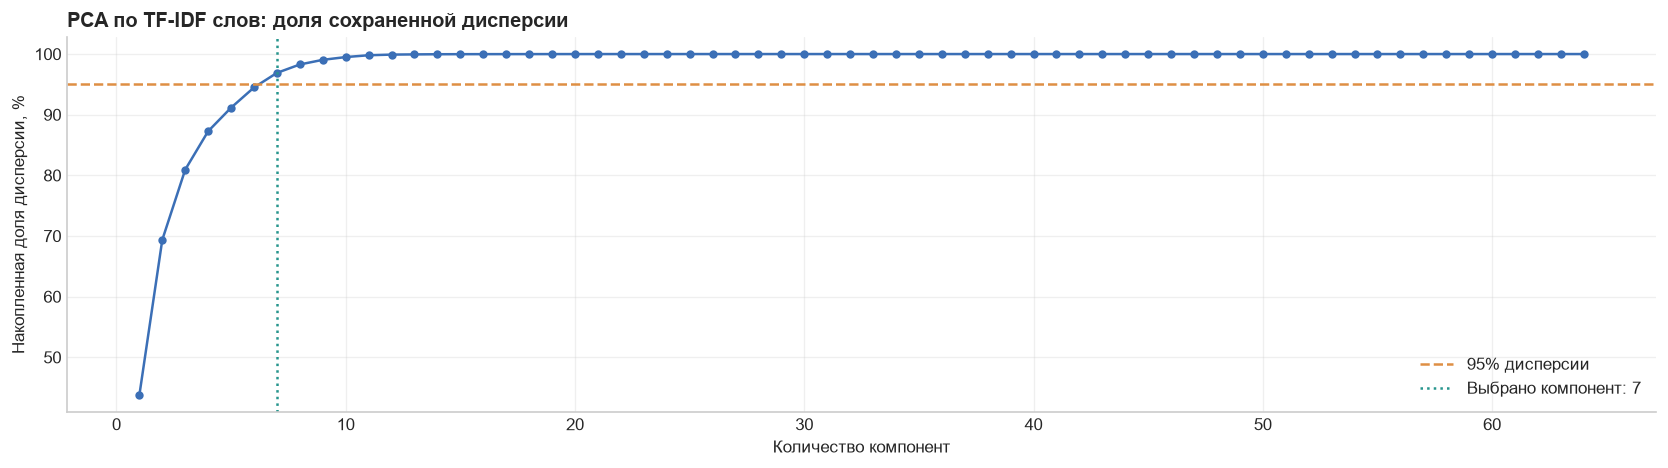

In [9]:
fig, ax = plt.subplots()
ax.plot(range(1, len(variance) + 1), variance, color="#3B6FB6", marker="o", markersize=4)
ax.axhline(95, color="#DE8F44", linestyle="--", label="95% дисперсии")
ax.axvline(n_components, color="#27958D", linestyle=":", label=f"Выбрано компонент: {n_components}")
ax.set_title("PCA по TF-IDF слов: доля сохраненной дисперсии")
ax.set_xlabel("Количество компонент")
ax.set_ylabel("Накопленная доля дисперсии, %")
ax.legend()
plt.tight_layout()
plt.show()

**Вывод:** Для 64 слов хватило 7 компонент, сохранили 96,9% дисперсии. Эти 7 компонент передаем дальше в KMeans и HDBSCAN.

## 2. KMeans

Теперь KMeans сравнивает сессии по словам после TF-IDF и PCA. Проверим от 2 до 10 кластеров на всех 575 061 сессии.

Выбираем максимальный силуэт: чем ближе он к 1, тем лучше группы отделены друг от друга. При одинаковой оценке оставим меньше кластеров. Метки аномалий не используем.

Сам силуэт считаем на одних и тех же 10 000 случайных сессий. Это ускоряет расчет, но редкие группы могут не попасть в оценку.

In [10]:
# Все модели обучаем на полном наборе. Силуэт оцениваем на одних и тех же 10 000 сессий.
score_indices = np.random.default_rng(42).choice(len(data), size=10_000, replace=False)
score_features = X_pca[score_indices]
kmeans_models = {}
k_rows = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    score_labels = model.labels_[score_indices]
    with config_context(working_memory=128):
        score = silhouette_score(score_features, score_labels)
    kmeans_models[k] = model
    k_rows.append({
        "Кластеров": k,
        "Силуэт": score,
    })

k_results = pd.DataFrame(k_rows)
best_score = k_results["Силуэт"].max()
best_k = int(k_results.loc[k_results["Силуэт"].eq(best_score), "Кластеров"].min())

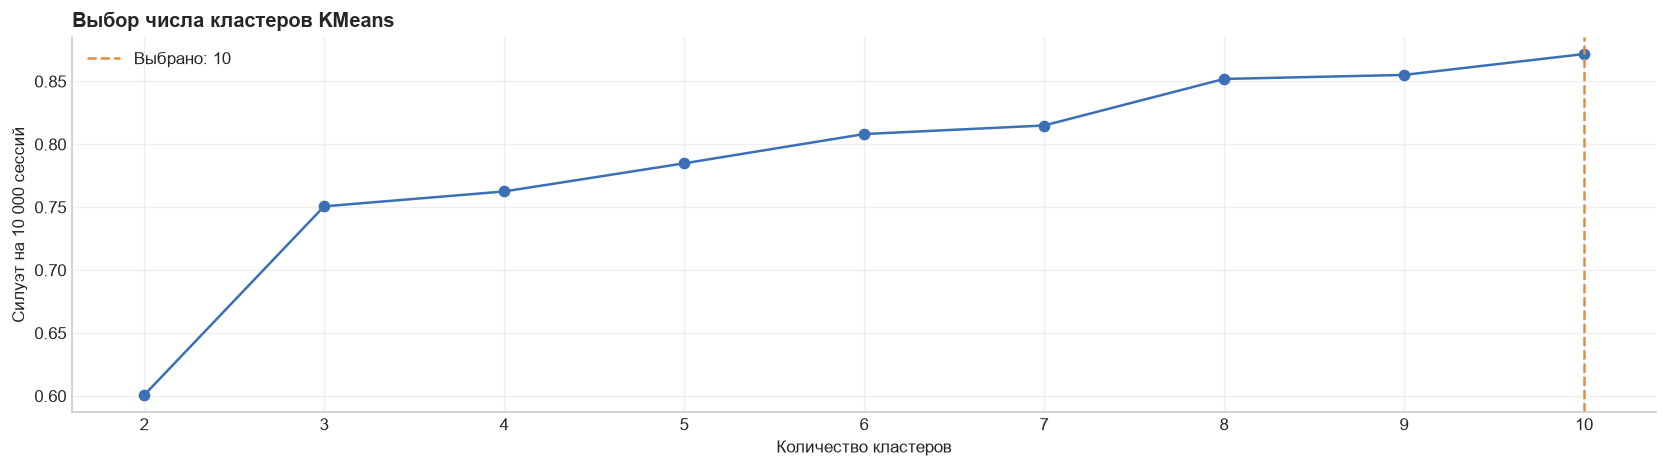

In [11]:
fig, ax = plt.subplots()
ax.plot(k_results["Кластеров"], k_results["Силуэт"], marker="o", color="#3B6FB6")
ax.axvline(best_k, color="#DE8F44", linestyle="--", label=f"Выбрано: {best_k}")
ax.set_title("Выбор числа кластеров KMeans")
ax.set_xlabel("Количество кластеров")
ax.set_ylabel("Силуэт на 10 000 сессий")
ax.set_xticks(range(2, 11))
ax.legend()
plt.tight_layout()
plt.show()

**Вывод:** Среди вариантов от 2 до 10 кластеров лучший силуэт у 10, 0,8717.

In [12]:
kmeans = kmeans_models[best_k]
data["kmeans"] = kmeans.labels_

kmeans_summary = data.groupby("kmeans").agg(
    Сессий=("BlockId", "size"),
    Аномальных=("is_anomaly", "sum"),
)
kmeans_summary["Нормальных"] = kmeans_summary["Сессий"] - kmeans_summary["Аномальных"]
kmeans_summary["Доля аномальных, %"] = kmeans_summary["Аномальных"] / kmeans_summary["Сессий"] * 100
display(kmeans_summary.round(2))

,Сессий,Аномальных,Нормальных,"Доля аномальных, %"
kmeans,,,,
0,304823,1140,303683,0.37
1,96533,216,96317,0.22
2,51071,558,50513,1.09
3,49769,306,49463,0.61
4,6212,6212,0,100.00
5,5329,5110,219,95.89
6,27795,151,27644,0.54
7,4684,2909,1775,62.11
8,5587,12,5575,0.21


**Вывод:** Самая большая группа - 304 823 сессии. Кластер 4 полностью аномальный: 6 212 из 6 212. В кластере 5 аномальных 95,9%, в кластере 7 - 62,1%. В кластерах 4, 5 и 7 суммарно 14 231 из 16 838 аномалий; еще 2 607 остались в других группах.

## 3. HDBSCAN

HDBSCAN ищет плотные группы, номер −1 означает «вне групп».

Используем TF-IDF и PCA для 589 разных наборов счетчиков событий, затем переносим группы на все сессии. Частоту повторов при обучении не учитываем. Это отдельный эксперимент, не запуск HDBSCAN на всех 575 061 строках.

Минимальный размер группы 20 разных наборов, `min_samples=5` задает требование к плотности соседей.

In [13]:
unique_mask = ~data[events].duplicated()
profiles = data.loc[unique_mask, events].copy()
hdbscan = HDBSCAN(min_cluster_size=20, min_samples=5, copy=True)
profiles["hdbscan"] = hdbscan.fit_predict(X_pca[unique_mask])

# Одинаковые счетчики получают одинаковый кластер; сохраняем все сессии.
data = data.merge(profiles, on=events, how="left", validate="many_to_one")


In [14]:
hdbscan_summary = data.groupby("hdbscan").agg(
    Сессий=("BlockId", "size"),
    Аномальных=("is_anomaly", "sum"),
)
hdbscan_summary["Разных наборов событий"] = profiles.groupby("hdbscan").size()
hdbscan_summary["Доля аномальных, %"] = hdbscan_summary["Аномальных"] / hdbscan_summary["Сессий"] * 100
display(hdbscan_summary.round(2))

,Сессий,Аномальных,Разных наборов событий,"Доля аномальных, %"
hdbscan,,,,
-1,415523,6535,71,1.57
0,4732,4516,84,95.44
1,604,601,32,99.50
2,24406,1372,37,5.62
3,74404,643,83,0.86
4,4505,2839,172,63.02
5,36,36,28,100.00
6,21515,248,25,1.15
7,29336,48,57,0.16


**Вывод:** Получилось 8 кластеров, еще 415 523 сессии остались вне групп. Аномальных среди них 6 535 — только 1,57%. Поэтому номер −1 не считаем признаком сбоя.

## 4. Сравнение KMeans и HDBSCAN

Оба метода используют те же 7 компонент PCA. KMeans распределяет все сессии по группам, HDBSCAN может оставить часть вне групп.

Сравним также группы, где **больше половины сессий аномальные по разметке авторов**. Посчитаем, сколько в них аномальных и нормальных сессий. Группу −1 сюда не включаем.

Это сравнение текущих результатов: KMeans обучен на всех 575 061 сессии, HDBSCAN - на 589 разных наборах без учета повторов. Итоги считаем по всем сессиям. Группы оцениваем по уже известным меткам, поэтому это не проверка поиска новых аномалий.

In [15]:
comparison_rows = []
for name, column in [("KMeans", "kmeans"), ("HDBSCAN", "hdbscan")]:
    groups = data.groupby(column)["is_anomaly"].agg(["size", "sum"])
    anomaly_share = groups["sum"] / groups["size"]
    selected = groups.loc[(anomaly_share > 0.5) & (groups.index != -1)]
    outside = data[column].eq(-1)
    selected_anomalies = int(selected["sum"].sum())

    comparison_rows.append({
        "Метод": name,
        "Кластеров": int((groups.index != -1).sum()),
        "Сессий вне кластеров": int(outside.sum()),
        "Аномальных вне кластеров": int(data.loc[outside, "is_anomaly"].sum()),
        "Групп с большинством аномальных": len(selected),
        "Аномальных в этих группах": selected_anomalies,
        "Нормальных в этих группах": int((selected["size"] - selected["sum"]).sum()),
        "Аномальных в остальных сессиях": int(data["is_anomaly"].sum()) - selected_anomalies,
    })

comparison = pd.DataFrame(comparison_rows).set_index("Метод").T
display(comparison)

Метод,KMeans,HDBSCAN
Кластеров,10,8
Сессий вне кластеров,0,415523
Аномальных вне кластеров,0,6535
Групп с большинством аномальных,3,4
Аномальных в этих группах,14231,7992
Нормальных в этих группах,1994,1885
Аномальных в остальных сессиях,2607,8846


**Вывод:** У KMeans получилось 10 кластеров, у HDBSCAN 8. HDBSCAN оставил 415 523 сессии вне групп, но аномальных среди них только 6 535.

В группах с большинством аномальных у KMeans собралась 14 231 аномальная сессия, у HDBSCAN 7 992. Нормальных там 1 994 и 1 885 соответственно.

По этому сравнению KMeans собрал больше аномалий в отдельных группах, при этом нормальных в них всего на 109 больше. Пока для нашей задачи он выглядит полезнее. Но условия обучения различаются, поэтому это вывод о текущих настройках и данных, а не о том, какой алгоритм лучше вообще.

Подписи групп получаем из данных: выбираем три слова, у которых средний TF-IDF в группе сильнее всего превышает средний по всем сессиям. Например, `transfer, ask, replicate` — слова о передаче и запросе копии блока. При изменении кластеров подписи пересчитаются. Это характерные слова, а не название сбоя.

In [16]:
words = vectorizer.get_feature_names_out()
overall_weights = X_words.mean(axis=0)
cluster_titles = {}

for column in ["kmeans", "hdbscan"]:
    cluster_titles[column] = {}
    for cluster in sorted(data[column].unique()):
        if cluster == -1:
            continue
        group_weights = X_words[data[column].eq(cluster)].mean(axis=0)
        difference = pd.Series(group_weights - overall_weights, index=words)
        top_words = difference[difference > 0].nlargest(3).index
        title = ", ".join(top_words) if len(top_words) else "Нет отличающих слов"
        cluster_titles[column][cluster] = title

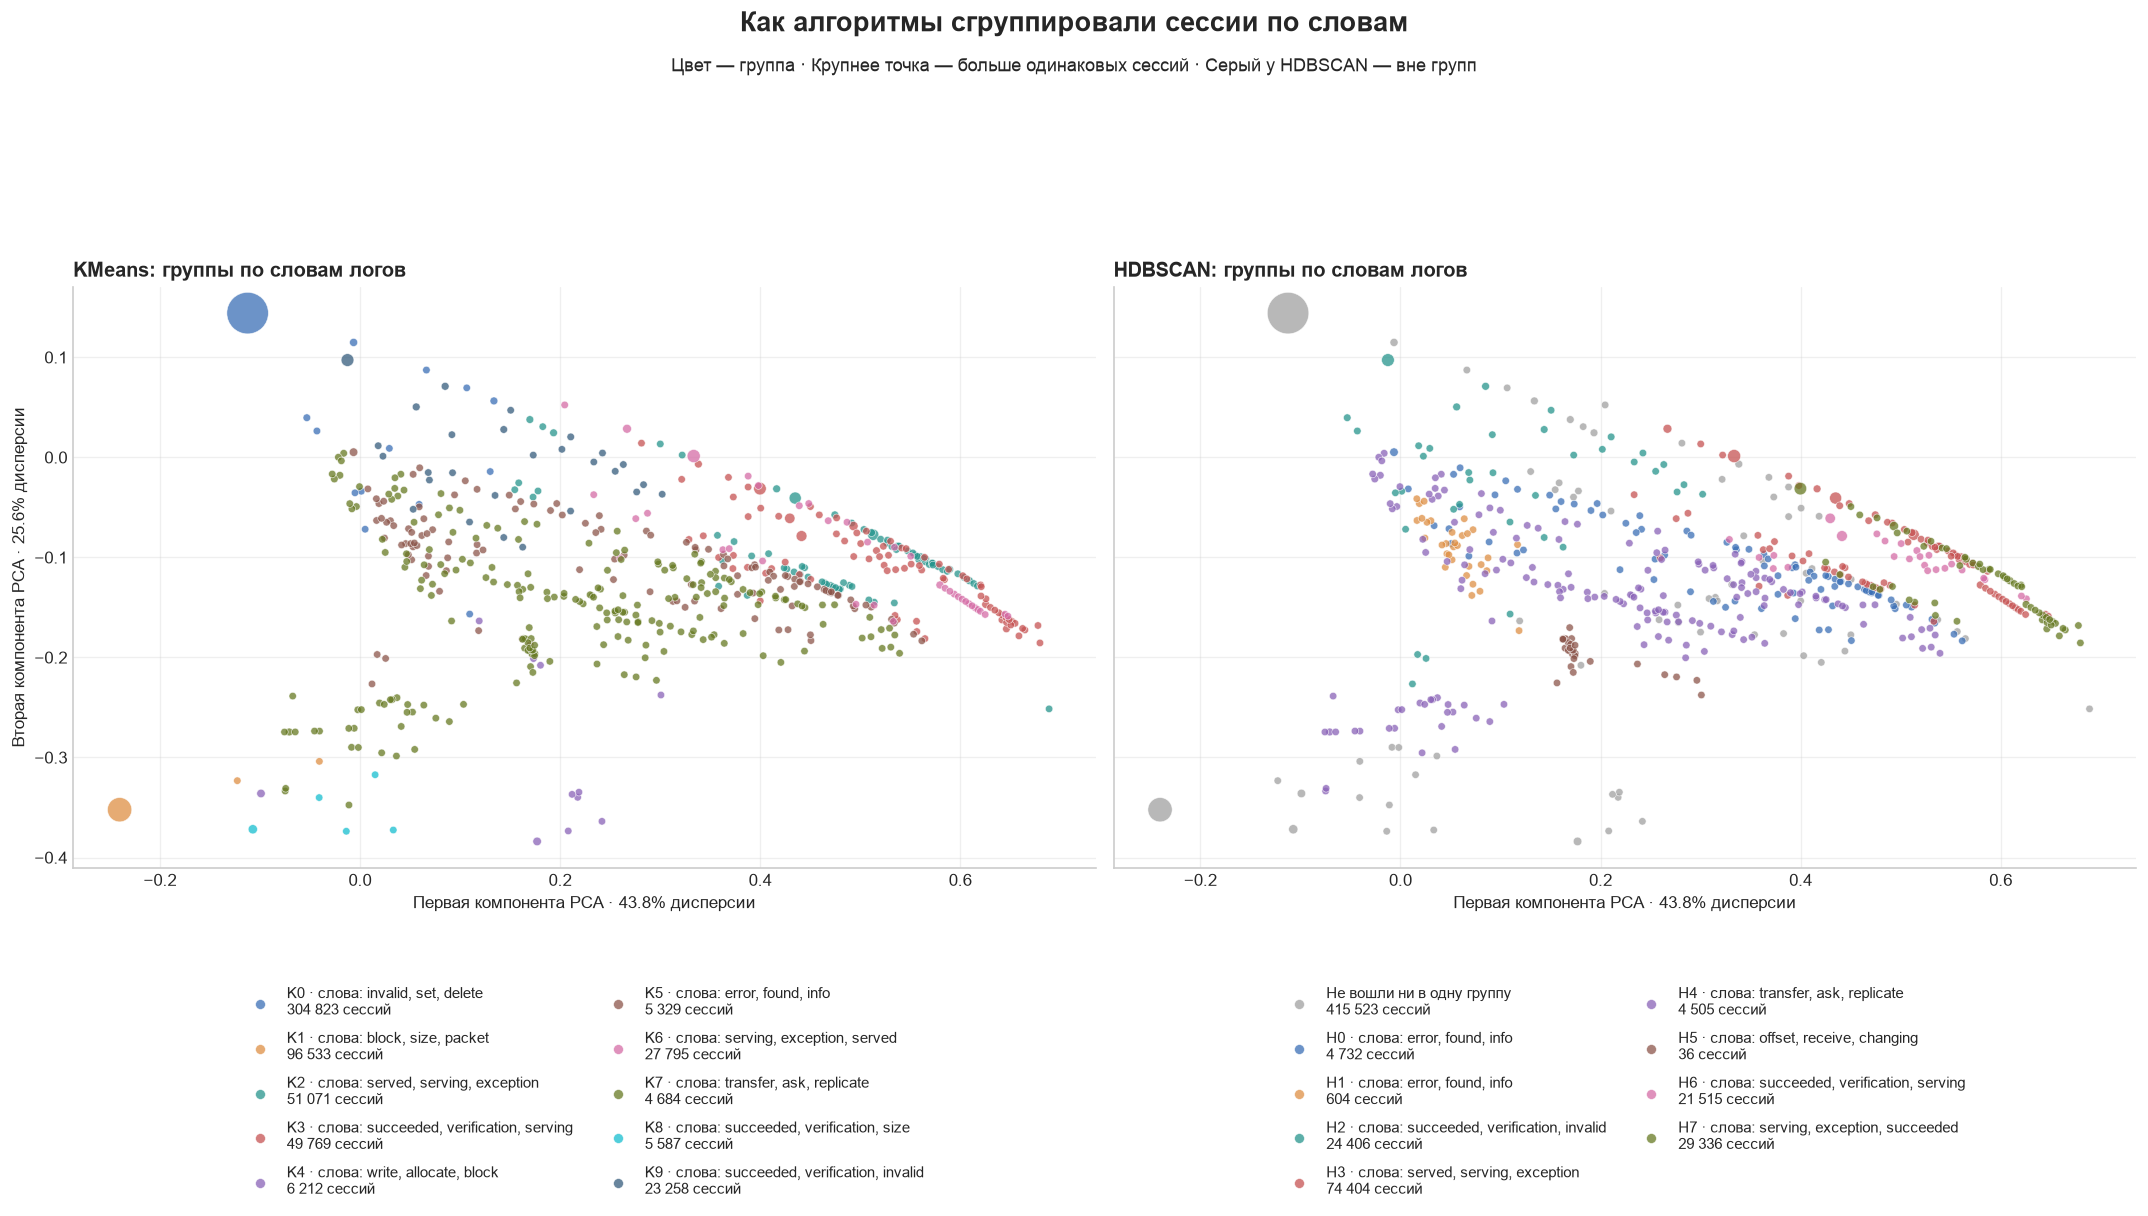

In [17]:
cloud = data.loc[unique_mask, events + ["kmeans", "hdbscan"]].copy()
cloud["x"] = X_pca[unique_mask, 0]
cloud["y"] = X_pca[unique_mask, 1]
session_counts = data.groupby(events).size().rename("sessions")
cloud = cloud.merge(session_counts, on=events, how="left", validate="one_to_one")
# Сначала рисуем большие точки, чтобы они не закрывали маленькие.
cloud = cloud.sort_values("sessions", ascending=False)

colors = ["#3B6FB6", "#DE8F44", "#27958D", "#C65353", "#8A63B8",
          "#8C564B", "#D56CA6", "#677A23", "#17BECF", "#355C7D"]
fig, axes = plt.subplots(1, 2, figsize=(18, 10), sharex=True, sharey=True)
for ax, method, column in zip(axes, ["KMeans", "HDBSCAN"], ["kmeans", "hdbscan"]):
    for cluster in sorted(cloud[column].unique()):
        group = cloud.loc[cloud[column].eq(cluster)]
        color = "#A0A0A0" if cluster == -1 else colors[cluster % len(colors)]
        prefix = "K" if column == "kmeans" else "H"
        description = cluster_titles[column].get(cluster, "")
        name = "Не вошли ни в одну группу" if cluster == -1 else f"{prefix}{cluster} · слова: {description}"
        count = f"{group['sessions'].sum():,}".replace(",", " ")
        ax.scatter(group["x"], group["y"], s=20 + group["sessions"] / 500,
                   color=color, alpha=0.75, edgecolors="white", linewidths=0.4,
                   label=f"{name}\n{count} сессий")
    ax.set_title(f"{method}: группы по словам логов")
    ax.set_xlabel(f"Первая компонента PCA · {pca.explained_variance_ratio_[0]:.1%} дисперсии")
    ax.set_aspect("equal", adjustable="box")
    legend = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9, labelspacing=0.8)
    for handle in legend.legend_handles:
        handle.set_sizes([35])
axes[0].set_ylabel(f"Вторая компонента PCA · {pca.explained_variance_ratio_[1]:.1%} дисперсии")
fig.suptitle("Как алгоритмы сгруппировали сессии по словам", fontsize=16, fontweight="bold")
fig.text(0.5, 0.93, "Цвет — группа · Крупнее точка — больше одинаковых сессий · Серый у HDBSCAN — вне групп",
         ha="center", fontsize=11)
plt.tight_layout()
plt.show()

**Вывод:** Это одни и те же сессии, но алгоритмы разделили их по-разному. KMeans отнес все точки к кластерам, HDBSCAN часть оставил серыми - вне групп. 

## Следующий шаг: эмбеддинги вместо мешка слов и TF-IDF

Эмбеддинги текстов шаблонов позволят учитывать смысл строк лога и могут помочь лучше разделить сессии на кластеры. Улучшение нужно проверить на данных.